In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import pandas as pd
import os
import cv2
import numpy as np

In [ ]:
from PIL import Image

def visualise_bboxes(prediction_df):
  # At least one prediction made per ground truth image
  images_list = prediction_df.image.unique()
  #images_list = list(map(lambda x: os.path.join(root, "test/" + x) , images_list))
  for image_name in images_list:
    im = Image.open(os.path.join(root, "test/test_images/" + image_name))
    #im_gt_df = ground_truth_df[ground_truth_df['filename'] == image_name]
    im_pred_df = prediction_df[prediction_df['image'] == image_name]
    im = im.resize(size=(320, 320))
    # draw bounding boxes on images
    fig, ax = plt.subplots()
    ax.imshow(im)
    print(image_name)
    print(len(im_pred_df))
    for _, row in im_pred_df.iterrows():
        x1 = row['x1']
        x2 = row['x2']
        y1 = row['y1']
        y2 = row['y2']
        width = abs(x2 - x1)
        height = abs(y2 - y1)
        
        rect = patches.Rectangle((x1, y1), width, height, linewidth=1, edgecolor='g', facecolor='none')
        label = row['class_pred']
        # only bboxes which look like there is an object within it will be kept.
        if row['prob_score'] > 0.6:
            # If there are objects of same category that are found elsewhere in the image, keep the object with the 
            # highest probability score. (Trade off: what if there are duplicates but we mark them as correct)
            ax.text(x1, y1, label, bbox=dict(facecolor='red', alpha=0.5))
            ax.add_patch(rect)
    plt.show()

In [ ]:
root = "./data_v1.1"
prediction_df = pd.read_csv("mobilenetV3.csv")

In [ ]:
visualise_bboxes(prediction_df)

/Users/ongyichong/opt/anaconda3/lib/python3.8/site-packages/torch/nn/modules/module.py:1051: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at  /Users/distiller/project/conda/conda-bld/pytorch_1623459044803/work/c10/core/TensorImpl.h:1156.)
  return forward_call(*input, **kwargs)
code/__torch__/torchvision/models/detection/faster_rcnn/___torch_mangle_146.py:1636: UserWarning: RCNN always returns a (Losses, Detections) tuple in scripting


tensor([ 50.2703, 153.3927,  70.7850, 182.5321]) tensor(9) tensor(0.9992)
tensor([ 87.2735, 205.1076, 103.7267, 231.0312]) tensor(8) tensor(0.9984)
tensor([173.9571, 239.0530, 190.2965, 272.1366]) tensor(6) tensor(0.9955)
tensor([243.9553, 162.3956, 259.5833, 187.9188]) tensor(3) tensor(0.9949)
tensor([128.2825, 237.5076, 148.7481, 265.5063]) tensor(7) tensor(0.9948)
tensor([147.4435,  23.7548, 182.0878,  48.0811]) tensor(12) tensor(0.9937)
tensor([210.8730, 229.9829, 230.1916, 251.6814]) tensor(5) tensor(0.9906)
tensor([ 43.0670, 114.5002,  67.8655, 136.4972]) tensor(10) tensor(0.9836)
tensor([ 33.3648,  17.6526, 276.4248, 294.2761]) tensor(13) tensor(0.9818)
tensor([240.5876, 193.4675, 255.3270, 217.5792]) tensor(4) tensor(0.9783)
tensor([66.4946, 50.2297, 88.3251, 87.3367]) tensor(11) tensor(0.9757)
tensor([233.8093, 106.3904, 257.1942, 122.8791]) tensor(2) tensor(0.9542)
tensor([209.9548,  58.5631, 219.8200,  78.5313]) tensor(1) tensor(0.8184)


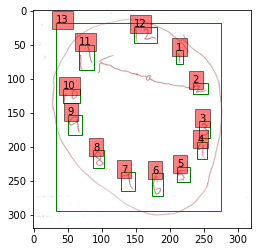

In [5]:
### ./test.png generated from user drawing input in IOS. Sanity check that image in IOS is in rendered correctly.
import torch
import torchvision

model = torch.jit.load("mobilenetv3_optimized.pt", map_location='cpu')
image = cv2.imread("./data_v1.1/test/test_images/27032021130128_MiD_1_1_1_1.png")
image = cv2.resize(image, dsize=(320, 320))
model.eval()
transform = torchvision.transforms.Compose([
     torchvision.transforms.ToTensor()
])
fig, ax = plt.subplots()
ax.imshow(image)
image = transform(image)
#image = image.unsqueeze(0)
_, output = model([image])
output = output[0]
# draw bounding boxes around image

for box, label, score in zip(output['boxes'], output['labels'], output['scores']):
    if score > 0.6:
        print(box, label, score)
        x1 = box[0].detach().numpy()
        y1 = box[1].detach().numpy()
        x2 = box[2].detach().numpy()
        y2 = box[3].detach().numpy()
        width = abs(x2 - x1)
        height = abs(y2 - y1)
        rect = patches.Rectangle((x1, y1), width, height, linewidth=1, edgecolor='g', facecolor='none')
        ax.text(x1, y1, label.detach().numpy(), bbox=dict(facecolor='red', alpha=0.5))
        ax.add_patch(rect)

plt.show()
        

In [ ]:
### Read in normalised pixel buffer generated by IOS into python. Check that the pixel buffer is correctly computed.

array = []
with open("output.txt", "r") as f:
    lines = f.readlines()
    for line in lines:
        array.append(float(line))
        
model = torch.jit.load("scripted_model_v2.pt", map_location='cpu')
tensor = torch.FloatTensor(array)
tensor = torch.reshape(tensor, (3, 320, 320))
#print(tensor.shape)
model([tensor])

In [ ]:
### Port python tensors over to C++

import torch

image1, image2 = cv2.imread("./test1.png"), cv2.imread("./sample_clock.png")
image1, image2 = cv2.resize(image1, dsize=(320, 320)), cv2.resize(image2, dsize=(320, 320))
transform = torchvision.transforms.Compose([
     torchvision.transforms.ToTensor()
])
tensor1, tensor2 = transform(image1), transform(image2)

class Container(torch.nn.Module):
    def __init__(self, my_values):
        super().__init__()
        for key in my_values:
            setattr(self, key, my_values[key])

my_values = {
    'test1': tensor1,
    'sample_clock': tensor2
}

container = torch.jit.script(Container(my_values))
container.save("container.pt")